# 03 · Modeling

**Goal:** compare models, handle class imbalance, and choose a decision threshold with a business argument.

Plan: Logistic Regression (baseline) → Random Forest → XGBoost, then threshold tuning.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # lets the notebook import src/

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

sns.set_theme(style="whitegrid")
ACCENT = "#941B50"
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (RocCurveDisplay, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, f1_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from src.train import build_pipeline, load_xy, make_preprocessor, split

X, y = load_xy()
X_train, X_test, y_train, y_test = split(X, y)
print(f"Train: {X_train.shape} | Test: {X_test.shape} | churn rate train {y_train.mean():.1%}, test {y_test.mean():.1%}")

Train: (5634, 21) | Test: (1409, 21) | churn rate train 26.5%, test 26.5%


## 1. Candidate models (5-fold cross-validation on the training set)

In [3]:
models = {
    "Logistic Regression": build_pipeline(X, y_train, "logreg", balanced=True),
    "Random Forest": Pipeline([("prep", make_preprocessor(X)),
                               ("model", RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                                                                class_weight="balanced", random_state=config.RANDOM_STATE, n_jobs=-1))]),
    "XGBoost": build_pipeline(X, y_train, "xgboost", balanced=True),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)
cv_results = {}
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:20s} ROC-AUC = {scores.mean():.3f} ± {scores.std():.3f}")

Logistic Regression  ROC-AUC = 0.846 ± 0.011
Random Forest        ROC-AUC = 0.845 ± 0.009
XGBoost              ROC-AUC = 0.845 ± 0.010


## 2. Evaluation on the test set

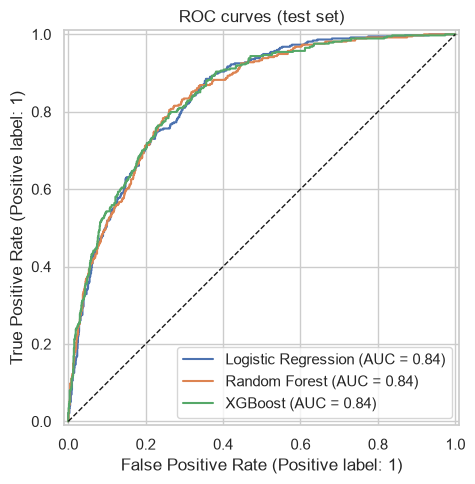

,roc_auc,recall,precision,f1
model,,,,
Logistic Regression,0.842,0.794,0.499,0.613
Random Forest,0.840,0.781,0.536,0.635
XGBoost,0.844,0.783,0.524,0.628


In [4]:
rows = []
fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({"model": name, "roc_auc": roc_auc_score(y_test, proba), "recall": recall_score(y_test, pred),
                 "precision": precision_score(y_test, pred), "f1": f1_score(y_test, pred)})
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set_title("ROC curves (test set)")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "03_roc_curves.png", dpi=150); plt.show()

comparison = pd.DataFrame(rows).set_index("model").round(3)
comparison.to_csv(config.ROOT / "reports" / "model_comparison.csv")
comparison

All three models use **class weights** to compensate the imbalance (`class_weight="balanced"` or XGBoost's `scale_pos_weight`).
Next, we compare with the other common approach: **SMOTE** (synthetic oversampling of churners).

## 3. Class weights vs. SMOTE (XGBoost)

In [5]:
from xgboost import XGBClassifier

smote_pipe = ImbPipeline([
    ("prep", make_preprocessor(X)),
    ("smote", SMOTE(random_state=config.RANDOM_STATE)),
    ("model", XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=4, subsample=0.8,
                            colsample_bytree=0.8, min_child_weight=3, eval_metric="auc", random_state=config.RANDOM_STATE)),
])
smote_scores = cross_val_score(smote_pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
print(f"XGBoost + class weights: {cv_results['XGBoost'].mean():.3f}")
print(f"XGBoost + SMOTE        : {smote_scores.mean():.3f}")

XGBoost + class weights: 0.845
XGBoost + SMOTE        : 0.845


## 4. Are the probabilities realistic? (calibration)

The dashboard multiplies each customer's monthly charge by their churn probability to get the **revenue at risk**.
That only makes sense if the probabilities are realistic: among customers scored 30%, about 30% should really churn.

Class weights (and SMOTE) **inflate** the probabilities: they make churners count more during training, so every
customer looks riskier than they are. The ranking (ROC-AUC) is unchanged, but the money figures would be overstated.
Let's check by comparing XGBoost with and without class weights.

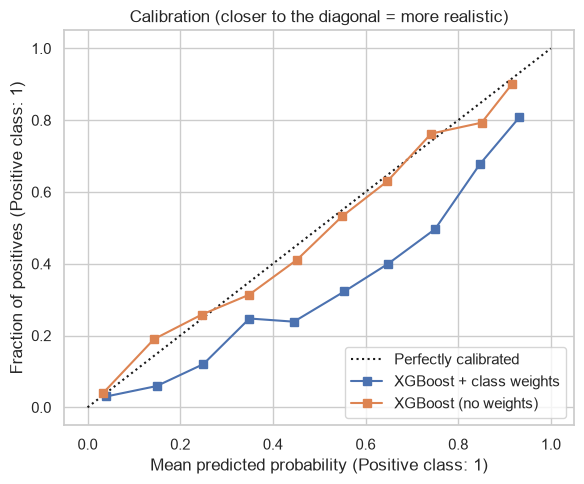

,roc_auc,brier,mean_predicted,actual_churn_rate,expected_churners,actual_churners
model,,,,,,
XGBoost + class weights,0.844,0.160,0.394,0.265,554.802002,374
XGBoost (no weights),0.844,0.136,0.266,0.265,374.209991,374


In [6]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

candidates = {
    "XGBoost + class weights": build_pipeline(X, y_train, "xgboost", balanced=True),
    "XGBoost (no weights)": build_pipeline(X, y_train, "xgboost", balanced=False),
}
rows = []
fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in candidates.items():
    p = pipe.fit(X_train, y_train).predict_proba(X_test)[:, 1]
    rows.append({"model": name, "roc_auc": roc_auc_score(y_test, p), "brier": brier_score_loss(y_test, p),
                 "mean_predicted": p.mean(), "actual_churn_rate": y_test.mean(),
                 "expected_churners": p.sum(), "actual_churners": int(y_test.sum())})
    CalibrationDisplay.from_predictions(y_test, p, n_bins=10, name=name, ax=ax)
ax.set_title("Calibration (closer to the diagonal = more realistic)")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "03_calibration.png", dpi=150); plt.show()
pd.DataFrame(rows).set_index("model").round(3)

**Reading the table:** both models have the same ROC-AUC (same ranking of customers), but only the unweighted model
predicts about as many churners as there really are (`expected_churners` ≈ `actual_churners`) and has the lower Brier score.

**Decision:** we keep **XGBoost without class weights** for the final model. Recall is not lost: it is recovered by
**lowering the decision threshold** in the next step. This gives both a high recall *and* trustworthy revenue figures.

## 5. Choosing the decision threshold

The default threshold 0.5 is arbitrary. The business question is:
*how many loyal customers are we willing to contact by mistake in order to catch more churners?*

Missing a churner costs a lost customer; contacting a loyal customer costs a call or a small discount.
So we favour **recall**, while keeping precision acceptable.

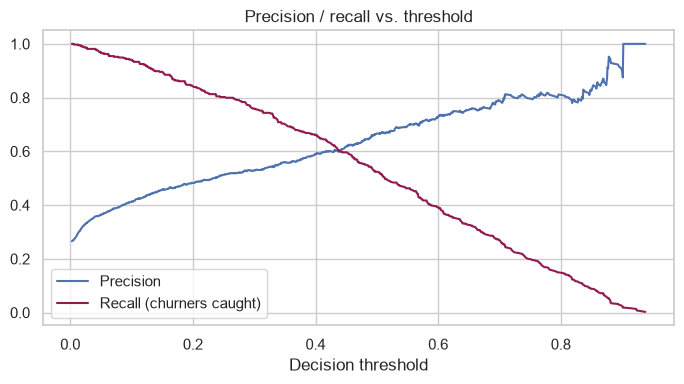

,threshold,precision,recall
0,0.003,0.265,1.000
117,0.011,0.289,0.997
234,0.019,0.316,0.992
351,0.034,0.347,0.981
468,0.066,0.379,0.955
585,0.111,0.424,0.933
702,0.163,0.465,0.880
819,0.244,0.510,0.805
936,0.346,0.558,0.703
1053,0.455,0.624,0.591


In [7]:
best = candidates["XGBoost (no weights)"]  # final model: realistic probabilities
proba = best.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_test, proba)
plt.figure(figsize=(7, 4))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall (churners caught)", color=ACCENT)
plt.xlabel("Decision threshold"); plt.legend(); plt.title("Precision / recall vs. threshold")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "03_threshold.png", dpi=150); plt.show()

table = pd.DataFrame({"threshold": thresholds, "precision": precision[:-1], "recall": recall[:-1]})
table.iloc[::len(table) // 12].round(3)

Chosen threshold: 0.23
Recall: 81.3% | Precision: 49.7% | ROC-AUC: 0.844


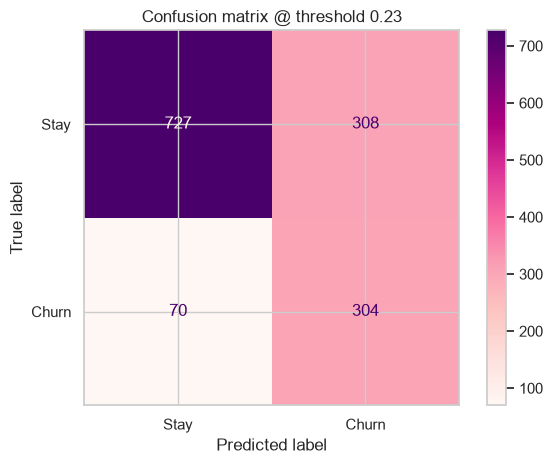

In [8]:
# Rule used here: the highest recall while keeping precision >= 50%
# (at least one contacted customer out of two is really at risk). Adjust MIN_PRECISION if you prefer.
MIN_PRECISION = 0.50
ok = table[table["precision"] >= MIN_PRECISION]
THRESHOLD = round(float(ok.loc[ok["recall"].idxmax(), "threshold"]), 2)

pred = (proba >= THRESHOLD).astype(int)
print(f"Chosen threshold: {THRESHOLD}")
print(f"Recall: {recall_score(y_test, pred):.1%} | Precision: {precision_score(y_test, pred):.1%} | ROC-AUC: {roc_auc_score(y_test, proba):.3f}")
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stay", "Churn"]).plot(cmap="RdPu")
plt.title(f"Confusion matrix @ threshold {THRESHOLD}")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "03_confusion_matrix.png", dpi=150); plt.show()

## 6. Business view of the result

In [9]:
test_df = X_test.assign(Churn=y_test.values, proba=proba, flagged=pred)
caught = test_df.query("Churn == 1 and flagged == 1")
missed = test_df.query("Churn == 1 and flagged == 0")
print(f"Churners caught: {len(caught)} / {int(y_test.sum())}")
print(f"Monthly revenue of caught churners: ${caught['MonthlyCharges'].sum():,.0f}")
print(f"Monthly revenue of missed churners: ${missed['MonthlyCharges'].sum():,.0f}")
print(f"Customers to contact: {int(pred.sum())} ({pred.mean():.0%} of the test set)")

Churners caught: 304 / 374
Monthly revenue of caught churners: $22,436
Monthly revenue of missed churners: $4,778
Customers to contact: 612 (43% of the test set)


## 7. Train and save the final model

This calls `src/train.py` (XGBoost without class weights) with your threshold: it re-evaluates on the test set, then refits on all customers and saves
`models/churn_model.joblib`. **Also write the threshold into `THRESHOLD` in `src/train.py`** so that running
`python -m src.train` from the terminal gives the same result.

In [10]:
from src import train
train.main(threshold=THRESHOLD)

ROC-AUC: 0.844 | Recall (churners) @ 0.23: 0.813
[[727 308]
 [ 70 304]]
              precision    recall  f1-score   support

        Stay       0.91      0.70      0.79      1035
       Churn       0.50      0.81      0.62       374

    accuracy                           0.73      1409
   macro avg       0.70      0.76      0.71      1409
weighted avg       0.80      0.73      0.75      1409

Model saved to C:\Users\USER\Desktop\churn-retention-dashboard\models\churn_model.joblib
